# Linear Regression

In [41]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Data Preprocessing

### **Exploring the dataset**

Let's start with loading the training data from the csv into a pandas dataframe



Load the datasets from GitHub. Train dataset has already been loaded for you in df below. To get test dataset use the commented code.

In [42]:
df = pd.read_csv('https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/train_processed_splitted.csv')

Let's see what the first 5 rows of this dataset looks like

In [43]:
df.head()

,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,Utilities,SalePrice
0,11553,1051,1159,336,0,5,AllPub,158000
1,8400,1052,1052,288,0,5,AllPub,138500
2,8960,1008,1028,360,0,6,AllPub,115000
3,11100,0,930,308,0,7,AllPub,84900
4,15593,1304,2287,667,0,4,AllPub,225000


What are all the features present? What is the range for each of the features along with their mean?

In [44]:
# Calculate summary statistics using describe()
stats = df.describe()

# Calculate the range (Max - Min)
feature_range = stats.loc['max'] - stats.loc['min']

# Get the mean
feature_mean = stats.loc['mean']

# Combine range and mean into a single DataFrame for easier visualization
summary_df = pd.DataFrame({
    'Mean': feature_mean,
    'Min': stats.loc['min'],
    'Max': stats.loc['max'],
    'Range': feature_range
})

print(summary_df)

                      Mean      Min       Max     Range
LotArea       10622.104262   1300.0  215245.0  213945.0
TotalBsmtSF    1058.311263      0.0    6110.0    6110.0
GrLivArea      1512.900304    334.0    5642.0    5308.0
GarageArea      473.480213      0.0    1418.0    1418.0
PoolArea          2.643075      0.0     738.0     738.0
OverallCond       5.582192      1.0       9.0       8.0
SalePrice    180795.504566  34900.0  755000.0  720100.0


### **Feature Scaling and One-Hot Encoding**

You must have noticed that some features `(such as Utilities)` are not continuous values.
  
These features contain values indicating different categories and must somehow be converted to numbers so that the computer can understand it. `(Computers only understand numbers and not strings)`
  
These features are called categorical features. We can represent these features as a `One-Hot Representation`
  
  
You must have also noticed that all the other features, each are in a different scale. This can be detremental to the performance of our linear regression model and so we normalize them so that all of them are in the range $[0,1]$

> NOTE: When you are doing feature scaling, store the min/max which you will use to normalize somewhere. This is then to be used at testing time. Try to think why are doing this?

In [45]:
df = pd.get_dummies(df, dtype=int, prefix='Utilities')


print(df)

      LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0       11553         1051       1159         336         0            5   
1        8400         1052       1052         288         0            5   
2        8960         1008       1028         360         0            6   
3       11100            0        930         308         0            7   
4       15593         1304       2287         667         0            4   
...       ...          ...        ...         ...       ...          ...   
1309     9020         1127       1165         490         0            7   
1310    10793          780       1620         462         0            5   
1311     8885          864        902         484         0            5   
1312    11275          710       2978         564         0            7   
1313    10206            0        944         528         0            3   

      SalePrice  Utilities_AllPub  Utilities_NoSeWa  
0        158000                 1

In [46]:
# Do the feature scaling here
#numerical features to be scaled:
features_to_scale = ['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea', 'OverallCond']

#storing the min and max in a dictionary
scaling_parameters = {}
for col in features_to_scale:
    col_min = df[col].min()
    col_max = df[col].max()
    scaling_parameters[col] = {'min': col_min, 'max': col_max}

    #applying Min-Max scaling formula: (x - min) / (max - min)
    df[col] = (df[col] - col_min) / (col_max - col_min)

print("Saved Scaling Parameters (to be used for testing later):")
import pprint #used for displaying our nested dictionaries cleanly
pprint.pprint(scaling_parameters)

print("\nFirst 5 rows of the scaled DataFrame:")
display(df.head())



Saved Scaling Parameters (to be used for testing later):
{'GarageArea': {'max': 1418, 'min': 0},
 'GrLivArea': {'max': 5642, 'min': 334},
 'LotArea': {'max': 215245, 'min': 1300},
 'OverallCond': {'max': 9, 'min': 1},
 'PoolArea': {'max': 738, 'min': 0},
 'TotalBsmtSF': {'max': 6110, 'min': 0}}

First 5 rows of the scaled DataFrame:


,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,SalePrice,Utilities_AllPub,Utilities_NoSeWa
0,0.047924,0.172013,0.155426,0.236953,0.0,0.500,158000,1,0
1,0.033186,0.172177,0.135268,0.203103,0.0,0.500,138500,1,0
2,0.035804,0.164975,0.130746,0.253879,0.0,0.625,115000,1,0
3,0.045806,0.000000,0.112283,0.217207,0.0,0.750,84900,1,0
4,0.066807,0.213421,0.367935,0.470381,0.0,0.375,225000,1,0


### **Conversion to NumPy**

Ok so now that we have all preprocessed all the data, we need to convert it to numpy for our linear regression model
  
Assume that our dataset has a total of $N$ datapoints. Each datapoint having a total of $D$ features (after one-hot encoding), we want our numpy array to be of shape $(N, D)$

In our task, we have to predict the `SalePrice`. We will need 2 numpy arrays $

*   List item
*   List item

(X, Y)$. These represent the features and targets respectively

In [47]:
# Convert to numpy array
# Separate features (X) and target (Y)
X = df.drop(columns=['SalePrice']).to_numpy()
Y = df['SalePrice'].to_numpy().reshape(-1, 1)
#here -1 tells NumPy to automatically figure out how many rows there should be according to the data.
#shaping in necessary as there would be shape mismatch error if not done while performing matrix multiplication.
print("Shape of X (Features)(N,D):", X.shape) #shape excludes sale price
print("Shape of Y (Target):", Y.shape)


Shape of X (Features)(N,D): (1314, 8)
Shape of Y (Target): (1314, 1)


## Linear Regression formulation
  
We now have our data in the form we need. Let's try to create a linear model to get our initial (Really bad) prediction


Let's say a single datapoint in our dataset consists of 3 features $(x_1, x_2, x_3)$, we can pose it as a linear equation as follows:
$$ y = w_1x_1 + w_2x_2 + w_3x_3 + b $$
Here we have to learn 4 parameters $(w_1, w_2, w_3, b)$
  
  
Now how do we extend this to multiple datapoints?  
  
  
Try to answer the following:
- How many parameters will we have to learn in the cae of our dataset? (Don't forget the bias term)
- Form a linear equation for our dataset. We need just a single matrix equation which correctly represents all the datapoints in our dataset
- Implement the linear equation as an equation using NumPy arrays (Start by randomly initializing the weights from a standard normal distribution)

In [48]:
# 1. Get the number of datapoints (N) and features (D).
N, D = X.shape

# 2. Initialize weights from a Standard Normal Distribution (mean=0, std=1)
# w has shape (1, D) which is (1, 8).
# w.T (transpose) has shape (D, 1) which is (8, 1).
np.random.seed(42) # Seeding for reproducibility
W = np.random.randn(1, D)

# 3. Initialize bias term (b) as a 2D matrix of shape (1, 1)
b = np.zeros((1, 1))
#reason for initializing b to a matrix of just 0:
#1) we would now be able to add with the matrix multiplication of weights and datapoints
#2)intializing to 0 doesnt mean it would stay at 0 at all times.later in code we will update the value to better fit our taining dataset.

# 4. Formulate the matrix equation to make our first prediction
# (N, D) @ (D, 1) -> (N, 1)
y_pred = X @ W.T + b
#the reason i put W.T is because my W is a row and the w in pdf given is a column.

print("Shape of weights (W):", W.shape)
print("Shape of bias (b):", b.shape)
print("Shape of initial predictions (y_pred):", y_pred.shape)

Shape of weights (W): (1, 8)
Shape of bias (b): (1, 1)
Shape of initial predictions (y_pred): (1314, 1)


How well does our model perform? Try comparing our predictions with the actual values

In [49]:
# comparing the first 5 predictions against their actual SalePrices
comparison = pd.DataFrame({
    'Actual SalePrice': Y.flatten()[:5],
    'Predicted SalePrice': y_pred.flatten()[:5]
})
#flatten is used to convert the 2D array to a 1D array. now it is simply like a series.y_pred.flatten is now converted from (N,1) to (N,).

display(comparison)

,Actual SalePrice,Predicted SalePrice
0,158000,1.923720
1,138500,1.851766
2,115000,1.899199
3,84900,1.829901
4,225000,2.449798


### **Learning weights using gradient descent**

So these results are really horrible. We need to somehow update our weights so that it correclty represents our data. How do we do that?

We must do the following:
- We need some numerical indication for our performance, for this we define a Loss Function ( $\mathscr{L}$ )
- Find the gradients of the `Loss` with respect to the `Weights`
- Update the weights in accordance to the gradients: $W = W - \alpha\nabla_W \mathscr{L}$

Lets define the loss function:
- We will use the MSE loss since it is a regression task. (Specify the assumptions we make while doing so as taught in the class).
- Implement this loss as a function. (Use numpy as much as possible)

In [50]:
def mse_loss_fn(y_true, y_pred):
      """
    Computes the Mean Squared Error (MSE) loss.

    Args:
        y_true: Ground truth target values of shape (N, 1)
        y_pred: Predicted target values of shape (N, 1)

    Returns:
        loss: The scalar MSE loss value
    """
      N = y_true.shape[0]
      #.shape[0] extracts the first dimention of its shape. here it is all the rows.
      loss = (1 / (2 * N)) * np.sum((y_pred - y_true) ** 2)
      #in the pdf given you have explicilty written +b inside the brackets. Here y_pred already contains that b.
      return loss


Calculate the gradients of the loss with respect to the weights (and biases). First write the equations down on a piece of paper, then proceed to implement it

In [51]:
def get_gradients(y_true, y_pred, W, b, X):
    """
    Calculates the gradients for the MSE loss function with respect to the weights (and bias)

    Args:
        y_true: The true values of the target variable (SalePrice in our case)
        y_pred: The predicted values of the target variable using our model (W*X + b)

        W: The weights of the model
        b: The bias of the model
        X: The input features
    """
    error  = y_pred - y_true
    N = y_true.shape[0]
    dW = (error.T @ X) / N
    #in reference to the PDF shared, z is basically error here. also in the pdf the numerator is just transposed.

    db = np.sum(error) / N
    """
    Returns:
        dW: The gradients of the loss function with respect to the weights
        db: The gradients of the loss function with respect to the bias
    """
    return dW, db


In [52]:
print(X.shape)
print(X.shape[0])
print(X.shape[1])

(1314, 8)
1314
8


Update the weights using the gradients

In [53]:
def update(weights, bias, gradients_weights, gradients_bias, lr):
    """
    Updates the weights (and bias) using the gradients and the learning rate

    Args:
        weights: The current weights of the model
        bias: The current bias of the model

        gradients_weights: The gradients of the loss function with respect to the weights
        gradients_bias: The gradients of the loss function with respect to the bias

        lr: The learning rate

    Returns:
        weights_new: The updated weights of the model

    """

    weights_new = weights - lr * gradients_weights
    bias_new = bias - lr * gradients_bias
    return weights_new, bias_new


Put all these together to find the loss value, its gradient and finally updating the weights in a loop. Feel free to play around with different learning rates and epochs
  
> NOTE: The code in comments are just meant to be used as a guide. You will have to do changes based on your code

In [54]:
NUM_EPOCHS = 100000
#take more epochs and use optimum learning rate for best predictions!
LEARNING_RATE = 2e-2

losses = []

for epoch in range(NUM_EPOCHS):
    y_pred = X @ W.T + b
    loss = mse_loss_fn(Y, y_pred)
    losses.append(loss)
    dw, db = get_gradients(Y, y_pred, W, b, X)
    W, b = update(W, b, dw, db, LEARNING_RATE)


Now use matplotlib to plot the loss graph

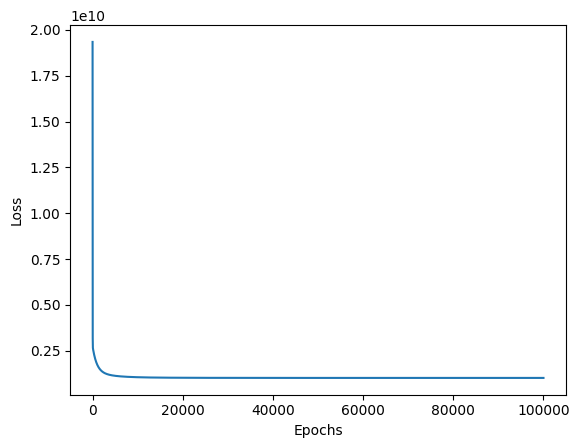

In [55]:
plt.plot(losses)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

### **Testing with test data**

Load and apply all the preprocessing steps used in the training data for the testing data as well. Remember to use the **SAME** min/max values which you used for the training set and not recalculate them from the test set. Also mention why we are doing this.

**Ans:** changing the min - max values would mean to change what an input would mean. if a model is trained on a particular set of input with some min and max, it has adjusted the weights accordingly. now if you scale some new input with new min and max then that input would mean something else for the model as this is scaled differently.

To load test data from GitHub, use the code below.


In [56]:
df_test = pd.read_csv('https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/test_processed_splitted.csv')
print(df_test)

if 'Utilities_AllPub' not in df_test.columns:
    df_test = df_test.join(pd.get_dummies(df_test['Utilities'], dtype = 'int32', prefix = 'Utilities'))
    df_test = df_test.drop('Utilities', axis = 1)

# Let's find all the columns that are missing in the test set
missing_cols = set(df.columns) - set(df_test.columns)

# Add these columns to the test set with all zeros
for col in missing_cols:
    df_test[col] = 0




     LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0      15623         2396       4476         813       555            5   
1      11952          808       1969         534         0            6   
2       7558          896       1913         342         0            6   
3       6762         1187       1208         632         0            5   
4       8529         1454       1434         527         0            5   
..       ...          ...        ...         ...       ...          ...   
141     9135         1536       1536         532         0            5   
142    11639         1428       1428         480         0            5   
143    11475         1584       1776         888         0            5   
144     5925          907       1131         672         0            7   
145    14559         1008       1363         288         0            7   

    Utilities  SalePrice  
0      AllPub     745000  
1      AllPub     190000  
2      AllPub     

Using the weights learnt above, predict the values in the test dataset. Also answer the following questions:
- Are the predictions good?
- What is the MSE loss for the testset
- Is the MSE loss for testing greater or lower than training
- Why is this the case

In [57]:
# Scale the features
features_to_scale = ['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea', 'OverallCond']
for feature in features_to_scale:
    col_min = scaling_parameters[feature]['min']
    col_max = scaling_parameters[feature]['max']
    df_test[feature] = (df_test[feature] - col_min) / (col_max - col_min)


# Fill NaN values
df_test.fillna(0, inplace=True)

# Scale features
print(df_test)

# Check for unexpected NaNs
nan_counts = df_test.isnull().sum()

print("Number of NaN values per column:")
print(nan_counts)

# Convert to numpy array
x_test = df_test.copy().drop('SalePrice', axis=1).to_numpy() # (N, D)
y_test = df_test.copy()['SalePrice'].to_numpy().reshape(-1, 1) # (N, 1)
print(x_test.shape)


      LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0    0.066947     0.392144   0.780332    0.573343  0.752033        0.500   
1    0.049788     0.132242   0.308026    0.376587  0.000000        0.625   
2    0.029251     0.146645   0.297476    0.241185  0.000000        0.625   
3    0.025530     0.194272   0.164657    0.445698  0.000000        0.500   
4    0.033789     0.237971   0.207234    0.371650  0.000000        0.500   
..        ...          ...        ...         ...       ...          ...   
141  0.036622     0.251391   0.226451    0.375176  0.000000        0.500   
142  0.048326     0.233715   0.206104    0.338505  0.000000        0.500   
143  0.047559     0.259247   0.271665    0.626234  0.000000        0.500   
144  0.021618     0.148445   0.150151    0.473907  0.000000        0.750   
145  0.061974     0.164975   0.193858    0.203103  0.000000        0.750   

     SalePrice  Utilities_AllPub  Utilities_NoSeWa  
0       745000                 1  

In [58]:
extra_cols = list(set(df_test.columns) - set(df.columns))
print("Extra columns in df_test:", extra_cols)

missing_cols = list(set(df.columns) - set(df_test.columns))
print("Missing columns in df_test:", missing_cols)

Extra columns in df_test: []
Missing columns in df_test: []


In [59]:
# Make predictions
y_pred_test = x_test @ W.T + b # (N, 1)
loss_test = mse_loss_fn(y_pred_test, y_test)


# Scale the predictions back to the original scale

#NO NEED TO SCALE.


In [60]:
idx = np.random.randint(0, x_test.shape[0], 5)
y_pred_test_sample = y_pred_test[idx].round().astype(int)
y_true_test_sample = y_test[idx].round().astype(int)

print('Predicted SalePrice: \t', y_pred_test_sample.squeeze().tolist())
print('Actual SalePrice: \t', y_true_test_sample.squeeze().tolist())
print('\nTest Loss: \t\t', loss_test)

Predicted SalePrice: 	 [203083, 207682, 180107, 87451, 58291]
Actual SalePrice: 	 [231500, 190000, 208900, 100000, 84000]

Test Loss: 		 1482838800.6598792
